# Compare bike results

Local trials requested by Tomislav. Team review pending. AI assistance: [record](../docs/AI_USE.md).

Read the frozen development results. Do not change settings after seeing them.

## Read the model comparison

 MAE is the average absolute error in rides per day. RMSE puts more weight on big errors.

,name,input_contract,mae,rmse,wape,days
0,blend_expanded_history_and_forecasts,expanded_history_and_forecasts,13263.417036,19635.939076,0.109978,92
1,blend_2023_history_and_forecasts,2023_history_and_forecasts,13494.129872,19180.379394,0.111891,92
2,control_existing_xgboost_cpu_seed42,2023_history_counts,14761.370650,23431.623432,0.122399,92
3,blend_expanded_history_counts,expanded_history_counts,14833.865188,22436.344763,0.123000,92
4,blend_2023_history_counts,2023_history_counts,15542.191105,23099.294610,0.128873,92
5,control_training_cv_seasonal_average,2023_history_counts,16063.381017,23477.599198,0.133195,92
6,control_lag1,2023_history_counts,17914.978261,27065.592069,0.148548,92
7,control_lag7,2023_history_counts,18476.902174,28229.779259,0.153208,92


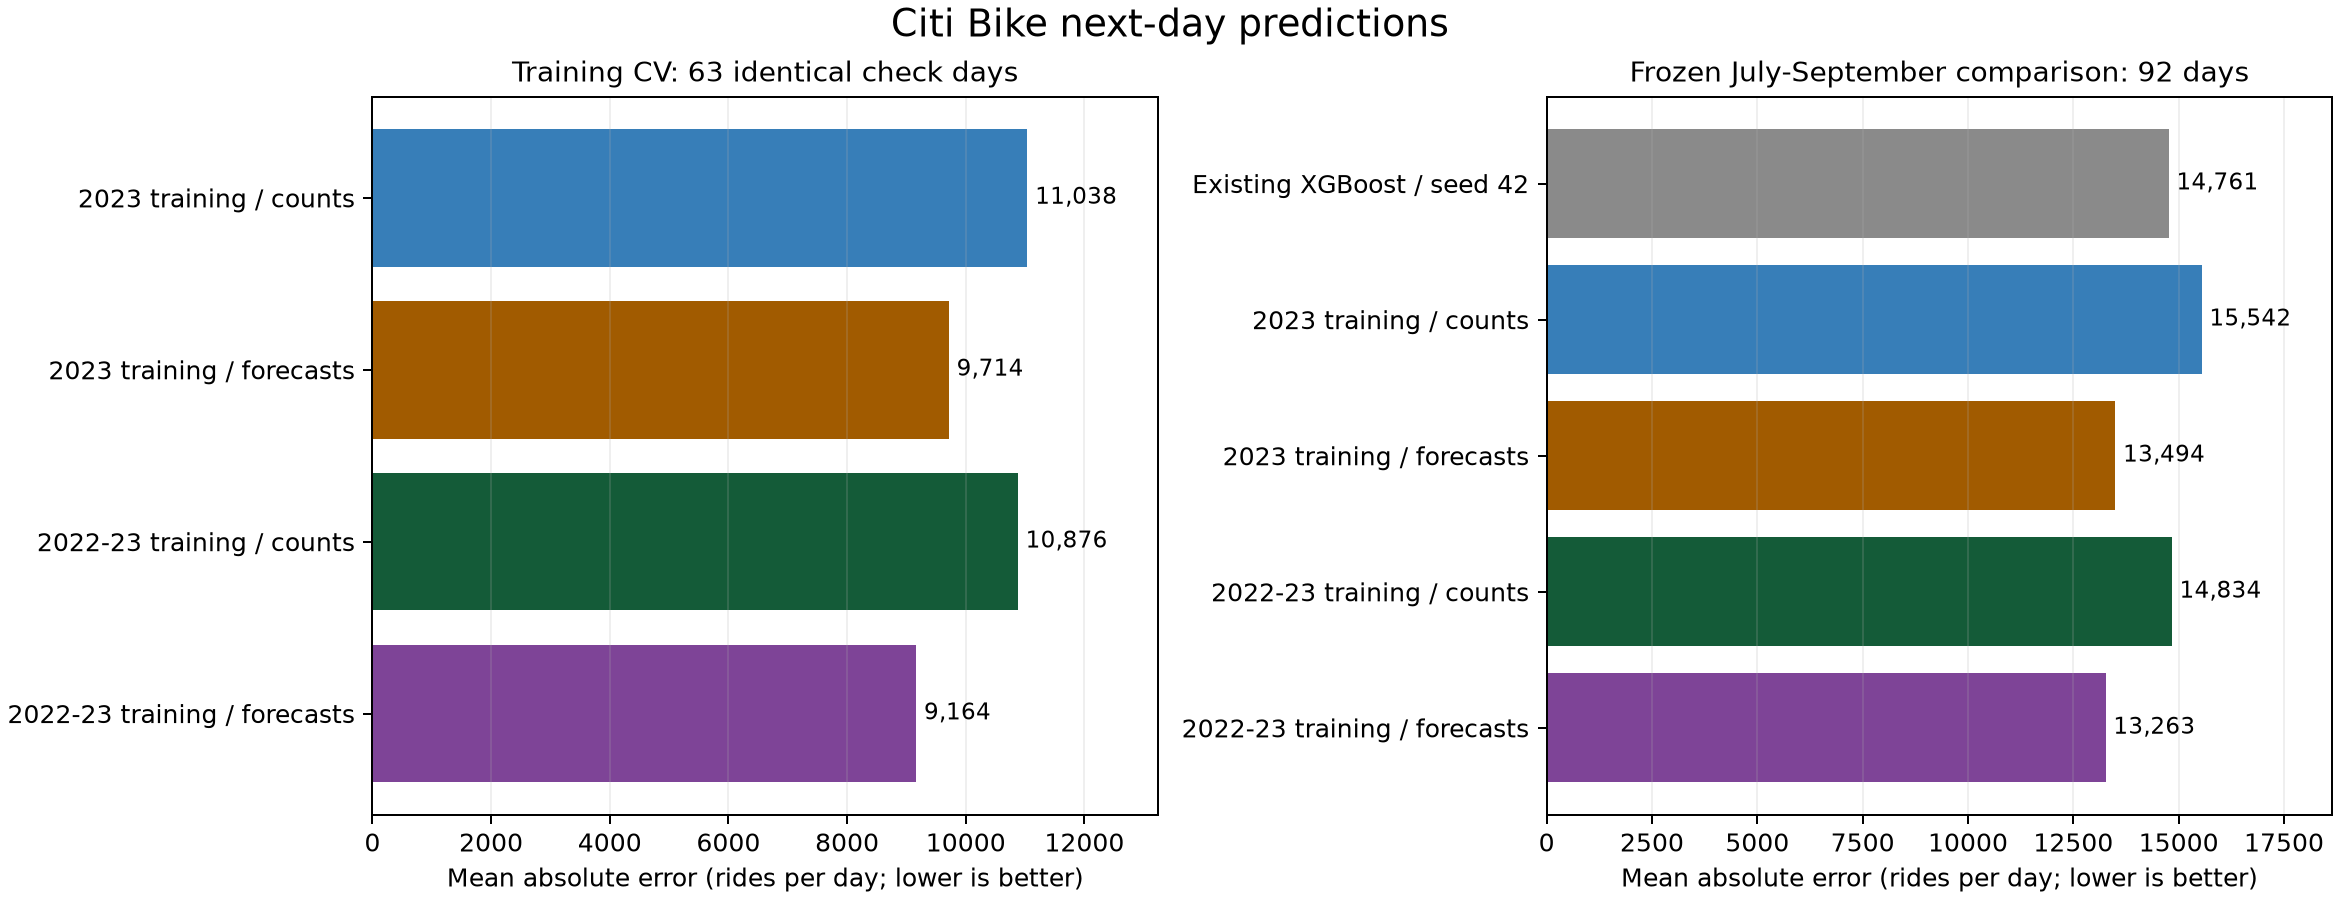

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
while not (ROOT / 'src/review_models.py').exists():
    if ROOT == ROOT.parent:
        raise RuntimeError('Open the notebook inside the review project.')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
results = pd.read_csv(ROOT / 'reports/research/frozen_validation_comparison.csv')
display(results[['name','input_contract','mae','rmse','wape','days']])
display(Image(filename=str(ROOT / 'reports/research/citibike_model_comparison.png')))

## Decision

Weather GRU/CatBoost has the lowest recorded MAE: 13,263. The CPU weather blend has MAE 13,494 and better RMSE. Counts-only research candidates do not beat XGBoost. Uncertainty checks still include no improvement.

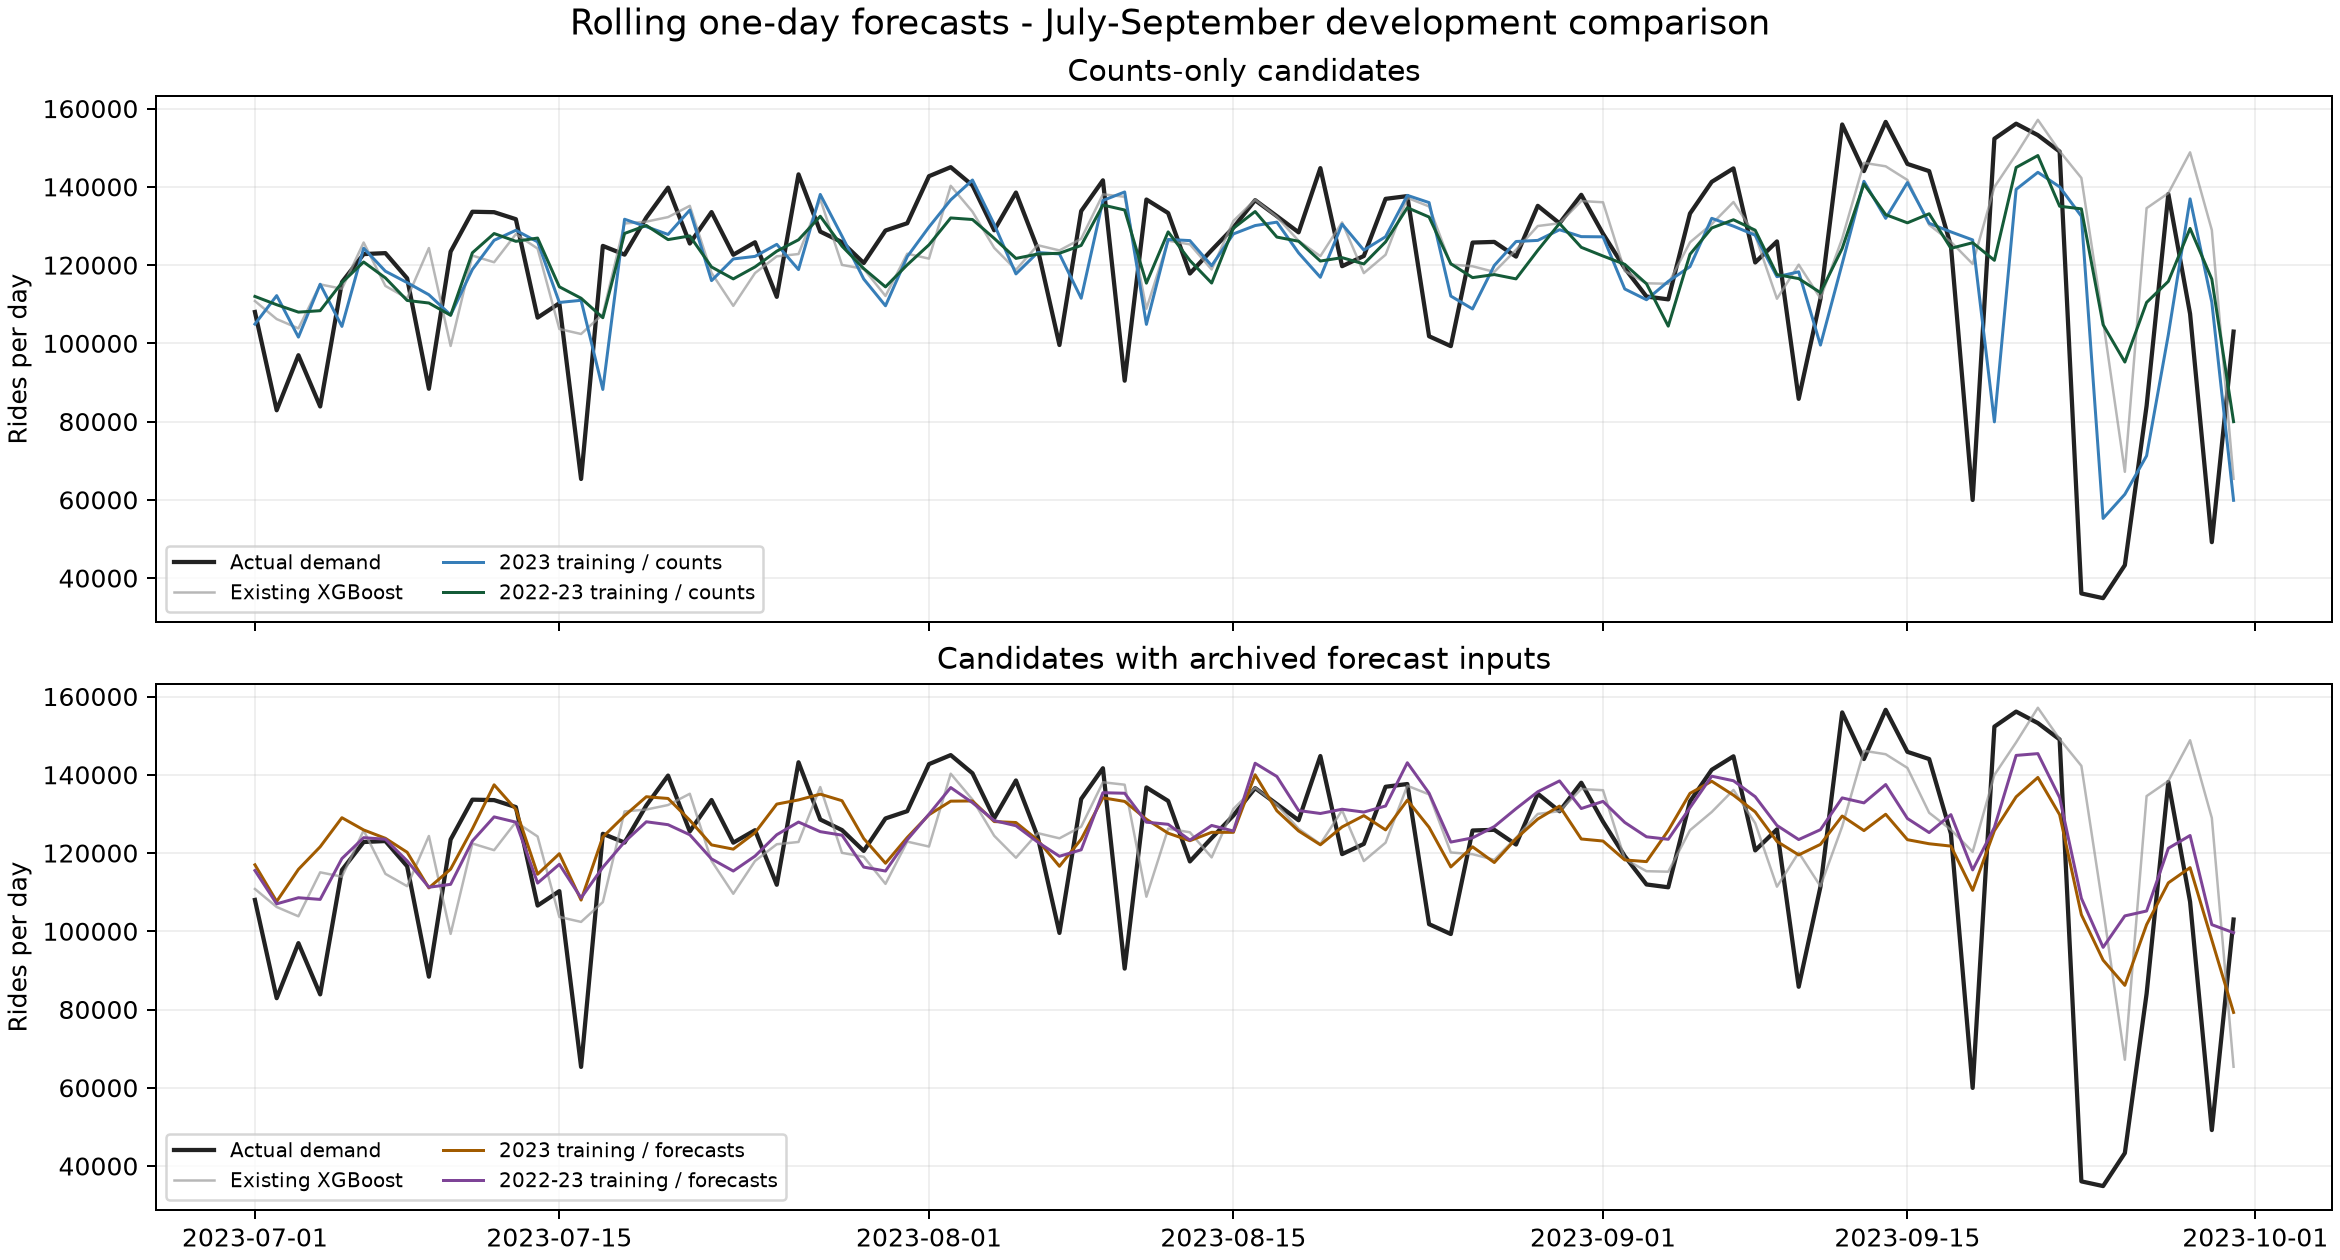

In [2]:
display(Image(filename=str(ROOT / 'reports/research/citibike_frozen_predictions.png')))

## The difficult days remain

 September was harder than July and August. On 23 September the actual count was 36,069; weather predictions were still about 104,000-108,000.

## Check the saved models

This is a training-side June input example, not an accuracy test. CPU weather needs eight dated forecast records. GRU weather needs one. Saved GRU inference runs on CPU.

In [3]:
from src.review_models import bike_example, predict_bike
for model in ['counts', 'weather_cpu', 'weather_gru']:
    display(predict_bike(bike_example(model)))

{'model': 'Counts-only XGBoost',
 'prediction_date': '2023-06-30',
 'predicted_rides': 119337,
 'unrounded_prediction': 119336.5478515625,
 'note': 'One-day forecast using completed prior counts. Historical example; no live feed is connected.'}

{'model': '75% SVR / 25% histogram boosting',
 'prediction_date': '2023-06-30',
 'predicted_rides': 124882,
 'unrounded_prediction': 124882.36263096887,
 'note': 'One-day forecast using completed prior counts. Historical example; no live feed is connected.'}

{'model': '75% GRU / 25% CatBoost',
 'prediction_date': '2023-06-30',
 'predicted_rides': 122094,
 'unrounded_prediction': 122094.28098957065,
 'note': 'One-day forecast using completed prior counts. Historical example; no live feed is connected.'}

## Next

Notebook 16 trains the CPU alternative on AWS. Notebook 17 is optional GPU training. Choose the release inputs before opening October-December targets.